# Essential Trigonometry

**Project:** AI-001 Mathematics for AI Engineering  
**Domain:** D01 — Mathematics, Statistics and Probability  
**Purpose:** Self-study reference and computational companion.

## Learning objective
Use radians, interpret sine/cosine/tangent, understand the unit circle and periodicity, and connect angular geometry to cosine similarity and sinusoidal positional representations.

> **Suggested approach:** Read each section, work through the algebra on paper, then run the code. Try the exercises without copying the examples. Keep a note of anything you cannot yet explain.

## Contents and study method

Work through the examples by hand before running the corresponding code. The code is there to check a result or explore a case; it is not a substitute for understanding the steps.

## 1. Angles and measurement

An angle measures rotation. Common units:
- degrees: a full turn is $360^\circ$;
- radians: a full turn is $2\pi$ radians.

Conversion:

$$
\text{radians}=\text{degrees}\times\frac{\pi}{180},
\qquad
\text{degrees}=\text{radians}\times\frac{180}{\pi}.
$$

Radians are the standard input convention in most numerical programming libraries.

In [1]:
import math
degrees = 90
radians = math.radians(degrees)
print(radians, math.degrees(radians))

1.5707963267948966 90.0


## 2. Sine, cosine and tangent

For a right triangle and acute angle $\theta$:

$$
\sin\theta=\frac{\text{opposite}}{\text{hypotenuse}},\quad
\cos\theta=\frac{\text{adjacent}}{\text{hypotenuse}},\quad
\tan\theta=\frac{\text{opposite}}{\text{adjacent}}.
$$

Also, where defined, $\tan\theta=\sin\theta/\cos\theta$.

These ratios describe relationships between angle and side lengths. The unit-circle definition extends them to all real angles.

In [2]:
import math
theta = math.radians(30)
print("sin:", math.sin(theta))
print("cos:", math.cos(theta))
print("tan:", math.tan(theta))

sin: 0.49999999999999994
cos: 0.8660254037844387
tan: 0.5773502691896257


## 3. Unit circle

The unit circle has radius 1 and centre at the origin. A point at angle $\theta$, measured from the positive x-axis, has coordinates

$$
(\cos\theta,\sin\theta).
$$

Thus cosine is the x-coordinate and sine is the y-coordinate. This gives meaning to trigonometric functions beyond right triangles and explains their periodicity.

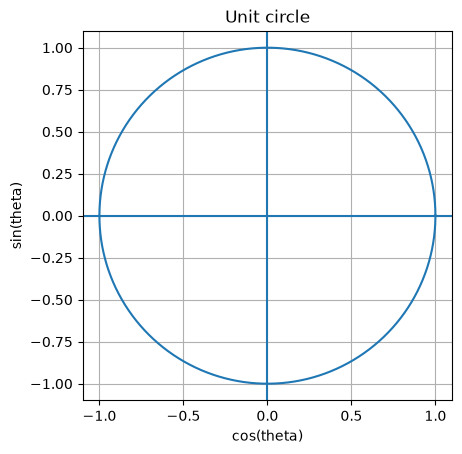

In [3]:
import numpy as np
import matplotlib.pyplot as plt

theta = np.linspace(0, 2*np.pi, 500)
plt.figure()
plt.plot(np.cos(theta), np.sin(theta))
plt.axhline(0)
plt.axvline(0)
plt.gca().set_aspect("equal", adjustable="box")
plt.title("Unit circle")
plt.xlabel("cos(theta)")
plt.ylabel("sin(theta)")
plt.grid(True)
plt.show()

## 4. Fundamental identities

The most important identity follows from the unit circle:

$$
\sin^2\theta+\cos^2\theta=1.
$$

Dividing by $\cos^2\theta$, where $\cos\theta\ne0$:

$$
1+\tan^2\theta=\sec^2\theta.
$$

The first identity is widely useful for simplifying expressions and understanding sinusoidal representations.

In [4]:
for angle in np.linspace(-2*np.pi, 2*np.pi, 9):
    lhs = math.sin(angle)**2 + math.cos(angle)**2
    assert math.isclose(lhs, 1.0, abs_tol=1e-12)
print("Identity verified numerically across sampled angles.")

Identity verified numerically across sampled angles.


## 5. Trigonometric functions and periodicity

Sine and cosine repeat every $2\pi$ radians:

$$
\sin(\theta+2\pi)=\sin\theta,\qquad
\cos(\theta+2\pi)=\cos\theta.
$$

Their outputs lie between -1 and 1. Tangent has period $\pi$ and is undefined where cosine is zero.

A sinusoid can be transformed by amplitude, frequency and phase, for example:

$$
y=A\sin(\omega x+\phi).
$$

Here $A$ controls amplitude, $\omega$ controls angular frequency, and $\phi$ controls phase shift.

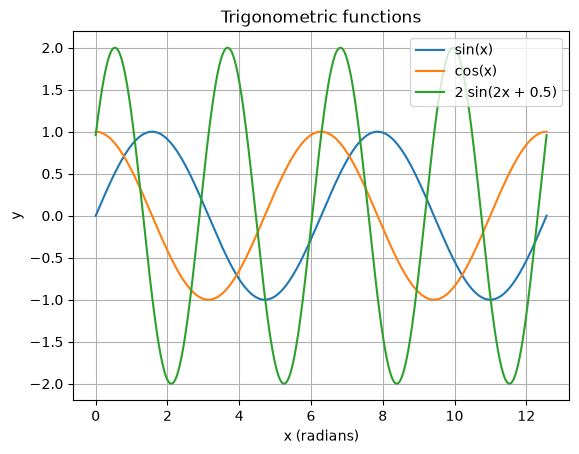

In [5]:
x = np.linspace(0, 4*np.pi, 500)
plt.figure()
plt.plot(x, np.sin(x), label="sin(x)")
plt.plot(x, np.cos(x), label="cos(x)")
plt.plot(x, 2*np.sin(2*x + 0.5), label="2 sin(2x + 0.5)")
plt.xlabel("x (radians)")
plt.ylabel("y")
plt.title("Trigonometric functions")
plt.grid(True)
plt.legend()
plt.show()

## 6. Angles between vectors and cosine similarity preview

For nonzero vectors $u$ and $v$, the angle $\theta$ between them satisfies

$$
\cos\theta=\frac{u\cdot v}{\|u\|\|v\|}.
$$

The right-hand side is cosine similarity. It measures directional alignment:
- near 1: similar direction;
- 0: perpendicular;
- near -1: opposite direction.

This is an important connection to embedding similarity and vector geometry. The full vector derivation belongs in Linear Algebra.

In [6]:
import numpy as np

u = np.array([1.0, 0.0])
v = np.array([1.0, 1.0])
cos_sim = np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v))
angle_degrees = np.degrees(np.arccos(cos_sim))
print("Cosine similarity:", cos_sim)
print("Angle in degrees:", angle_degrees)

Cosine similarity: 0.7071067811865475
Angle in degrees: 45.00000000000001


## 7. Sinusoidal positional encoding connection

Transformer positional encodings have used sine and cosine functions at different frequencies. A simplified view is that position information is represented by periodic signals with multiple wavelengths.

The key ideas are:
- sine/cosine are periodic;
- changing frequency changes the rate of oscillation;
- using multiple frequencies provides patterns at different scales.

The full positional-encoding equations and their design trade-offs belong in the Transformer mathematics section.

## 8. Practice

1. Convert $150^\circ$ to radians.
2. Convert $3\pi/4$ radians to degrees.
3. State the unit-circle coordinates at $\theta=0$, $\pi/2$ and $\pi$.
4. Verify $\sin^2\theta+\cos^2\theta=1$ for $\theta=\pi/3$.
5. What does cosine similarity equal for perpendicular nonzero vectors?
6. Explain why a Transformer might use multiple sinusoidal frequencies rather than a single sine wave.

**Where this appears in AI/ML:** Trigonometry supports angular similarity, vector geometry and periodic positional representations. Prioritise radians, unit-circle intuition, sine/cosine and cosine similarity over lengthy identity memorisation.